# 신항 1~5부두: 선석점유율 · 선석당 처리량 · 점유시간당 처리량

2022년 1월~2025년 12월, 월별·부두별로 계산합니다. **시설 지정기간 기준의 잠정 지표**입니다. 실제 접안·이안 시간 또는 모든 선종을 포함한 점유율이 아닙니다.

- 지정자료: 풀컨테이너선의 시설 지정기간을 선석별로 합집합 처리합니다. 사용목적은 기본적으로 전부 포함합니다. 대기·수리도 선석을 차지하기 때문입니다.
- `port_month.csv`: 천TEU를 **TEU로 1,000배 변환**하여 사용합니다. 파일에 다른 단위가 있으면 실행을 중단합니다.
- `record_except_168.csv`: 재항시간 재계산, 동일 호출부호의 입출항기간과 지정기간 겹침 확인에 사용합니다. 168시간 이상이 제외된 자료이므로 이를 이용해 점유시간을 삭제하거나 보정하지 않습니다.

**전제와 한계**

1. 운영 선석 목록은 외부 검증 없이 지정자료에 등장한 목록으로 초기 설정했습니다. 이는 실제 운영 선석 수의 확정값이 아닙니다. 실제 목록과 운영 개시·중단 이력을 확인한 후 설정을 수정하세요. 기본 제공 가능 시간은 각 선석 24시간 × 해당 월 일수입니다.
2. 지정자료의 선종 범위(풀컨테이너선)와 부두 전체 물동량의 범위가 완전히 같은지 확인이 필요합니다. 따라서 점유시간당 TEU는 **잠정 비율**이며 크레인 생산성이나 실제 작업시간당 생산성이 아닙니다.
3. 파일명이 '지정기간내'인 만큼 월 경계를 넘는 기록이 추출에서 빠졌는지 원자료 추출 조건을 확인해야 합니다. 이 코드는 포함된 기록은 월 경계에서 정확히 자르지만, 파일에 없는 기록을 복구하지는 못합니다.
4. 자료에 없는 지정시간은 0시간으로 집계합니다. 이는 해당 기간의 추출자료가 완전하다는 가정이며, 무기록과 실제 미점유를 구분할 수 없습니다.
5. 신항 4부두 4선석은 단 1건입니다. 기본값에는 포함하되 아래에서 제외 시나리오도 비교합니다.

실행 환경: Python 3.10 이상, pandas, numpy, matplotlib. 설치: `%pip install pandas numpy matplotlib`
세 CSV를 노트북이 실행되는 위치의 `data` 폴더에 두세요. `load_dataset()`에 확장자를 제외한 파일명을 전달합니다. 그래프의 제목·축·범례는 한글로 표시합니다. Windows의 맑은 고딕 글꼴을 사용합니다.

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def load_dataset(filename):
    BASE_DIR = '../data'
    EXTENSION = '.csv'
    TARGET_PATH = f'{BASE_DIR}/{filename}{EXTENSION}'
    try:
        return pd.read_csv(TARGET_PATH)
    except FileNotFoundError:
        return None
    except UnicodeDecodeError:
        return pd.read_csv(TARGET_PATH, encoding = 'euc-kr')

from pathlib import Path
from matplotlib.ticker import PercentFormatter

MONTHS = pd.date_range('2022-01-01', '2025-12-01', freq='MS')
START, END = MONTHS[0], pd.Timestamp('2026-01-01')
PIERS = [f'신항{i}부두' for i in range(1, 6)]

# None이면 자료에 등장한 목록 사용: 반드시 실제 운영 목록과 대조하세요.
# 예: {'신항1부두': [1, 2, 3], ...}처럼 다섯 부두 전체를 지정합니다.
BERTHS_BY_PIER = None
# 실제 가동 중단·개장 이력이 있으면, 뒤에서 만드는 availability_hours를 수정하세요.
# 지정목적 제한이 필요하면 ['양적하', '양하', '적하'] 등으로 변경.
PURPOSES = None

def facility_parts(series):
    parts = series.astype('string').str.extract(r'신항\s*(\d+)\s*부두\s*(\d+)\s*선석')
    return '신항' + parts[0] + '부두', pd.to_numeric(parts[1], errors='coerce')

# ./data 폴더의 CSV 파일명 (확장자 제외)
designation_raw = load_dataset('berth_window')
volume_raw = load_dataset('port_month')
record_raw = load_dataset('record_except_168')

# 누락 파일은 계산 전에 확인합니다.
for filename, dataset in [
    ('berth_window', designation_raw),
    ('port_month', volume_raw),
    ('record_except_168', record_raw),
]:
    if dataset is None:
        raise FileNotFoundError(f'./data/{filename}.csv 파일을 확인해주세요.')

DESIGNATION_FILE = 'berth_window.csv'
VOLUME_FILE = 'port_month.csv'
RECORD_FILE = 'record_except_168.csv'
display(pd.DataFrame({'파일': [DESIGNATION_FILE, VOLUME_FILE, RECORD_FILE],
                      '행수': [len(designation_raw), len(volume_raw), len(record_raw)]}))


,파일,행수
0,berth_window.csv,20981
1,port_month.csv,117
2,record_except_168.csv,19981


## 1. 기간·시설 정리와 자료 점검
잘못된 기간과 완전 중복은 별도 집계합니다. 같은 선박의 재신청·기간 연장이 겹쳐도 나중에 합집합으로 한 번만 계산합니다. 재신청 이력인지 단순 중복 지정인지는 별도 원자료 확인이 필요합니다.

In [23]:
d = designation_raw.copy()
d['부두'], d['선석'] = facility_parts(d['지정시설명'])
d['시작'] = pd.to_datetime(d['지정기간시작'], errors='coerce')
d['종료'] = pd.to_datetime(d['지정기간종료'], errors='coerce')
bad = d['시작'].isna() | d['종료'].isna() | d['종료'].le(d['시작']) | d['부두'].isna() | d['선석'].isna()
invalid_designations = d.loc[bad].copy()
exact_duplicates = d.duplicated(subset=designation_raw.columns)
d = d.loc[~bad & ~exact_duplicates].copy()
d = d.loc[d['부두'].isin(PIERS) & d['시작'].lt(END) & d['종료'].gt(START)].copy()
if PURPOSES is not None:
    d = d.loc[d['사용목적명'].isin(PURPOSES)].copy()
d['선석'] = d['선석'].astype(int)
observed_inventory = d.groupby(['부두', '선석']).agg(지정건수=('호출부호','size'), 최초지정=('시작','min'), 최종지정=('종료','max')).reset_index()
if BERTHS_BY_PIER is None:
    BERTHS_BY_PIER = {p: sorted(d.loc[d['부두'].eq(p), '선석'].unique().tolist()) for p in PIERS}
assert set(BERTHS_BY_PIER) == set(PIERS)
assert all(len(v) > 0 and len(v) == len(set(v)) for v in BERTHS_BY_PIER.values())
selected = d.apply(lambda row: row['선석'] in BERTHS_BY_PIER[row['부두']], axis=1)
excluded_inventory = d.loc[~selected].copy()
d = d.loc[selected].copy()
print('기간/시설 오류:', len(invalid_designations), '| 완전 중복:', int(exact_duplicates.sum()))
print('설정 목록 밖의 기록:', len(excluded_inventory))
print('잠정 운영 선석 목록:', BERTHS_BY_PIER)
display(observed_inventory)
display(d['사용목적명'].value_counts().rename_axis('사용목적').reset_index(name='건수'))


기간/시설 오류: 0 | 완전 중복: 0
설정 목록 밖의 기록: 0
잠정 운영 선석 목록: {'신항1부두': [1, 2, 3], '신항2부두': [1, 2, 3, 4, 5], '신항3부두': [1, 2, 3, 4], '신항4부두': [1, 2, 3, 4], '신항5부두': [1, 2, 3, 4]}


,부두,선석,지정건수,최초지정,최종지정
0,신항1부두,1,1262,2022-01-01 06:00:00,2025-12-30 16:00:00
1,신항1부두,2,1053,2022-01-02 08:00:00,2025-12-31 00:01:00
2,신항1부두,3,902,2022-01-01 02:00:00,2025-12-29 23:00:00
3,신항2부두,1,1708,2022-01-01 03:00:00,2025-12-30 20:00:00
4,신항2부두,2,1532,2022-01-01 05:00:00,2025-12-31 17:00:00
5,신항2부두,3,1292,2022-01-01 08:00:00,2025-12-30 16:00:00
6,신항2부두,4,1126,2022-01-01 08:00:00,2025-12-30 20:00:00
7,신항2부두,5,1038,2022-01-01 20:00:00,2025-12-31 22:00:00
8,신항3부두,1,755,2022-01-02 14:00:00,2025-12-31 20:00:00
9,신항3부두,2,479,2022-01-04 07:00:00,2025-12-31 05:00:00


,사용목적,건수
0,양적하,19884
1,적하,498
2,양하,484
3,접안대기,59
4,기타,23
5,출항대기,14
6,수리,12
7,급유,6
8,통과선박,1


## 2. 선석별 지정시간 합집합 → 월별 점유시간
기간은 `[시작, 종료)`로 취급합니다. 같은 선석에서 겹치거나 이어진 기간을 합친 후 월별로 분할합니다. 다른 선석의 동시 사용시간은 각각 더합니다.

- 선석점유율(%) = 지정기간 합집합 시간 ÷ 제공 가능 선석시간 × 100
- 선석당 처리량(TEU/선석·월) = 월 물동량 ÷ 설정된 운영 선석 수
- 점유시간당 처리량(TEU/선석시간) = 월 물동량 ÷ 전체 선석 점유시간

점유시간이 0이면 마지막 지표는 NaN으로 둡니다.

In [24]:
def merge_intervals(pairs):
    merged = []
    for start, end in sorted(pairs):
        if end <= start:
            continue
        if merged and start <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(end, merged[-1][1]))
        else:
            merged.append((start, end))
    return merged

# 짧은 검증: 중복된 2개 구간은 3시간으로 합쳐져야 합니다.
t0 = pd.Timestamp('2022-01-01')
assert sum((e-s).total_seconds()/3600 for s,e in merge_intervals([
    (t0,t0+pd.Timedelta(hours=2)), (t0+pd.Timedelta(hours=1),t0+pd.Timedelta(hours=3))])) == 3

merged_rows = []
for (pier, berth), group in d.groupby(['부두','선석']):
    pairs = [(max(s, START), min(e, END)) for s,e in zip(group['시작'], group['종료'])]
    for s,e in merge_intervals(pairs):
        merged_rows.append((pier, berth, s, e))
merged_intervals = pd.DataFrame(merged_rows, columns=['부두','선석','합집합시작','합집합종료'])

berth_rows = []
for pier in PIERS:
    for berth in BERTHS_BY_PIER[pier]:
        g = merged_intervals.loc[merged_intervals['부두'].eq(pier) & merged_intervals['선석'].eq(berth)]
        for month in MONTHS:
            next_month = month + pd.offsets.MonthBegin(1)
            occupied = sum(max(0.0, (min(e,next_month)-max(s,month)).total_seconds()/3600)
                           for s,e in zip(g['합집합시작'], g['합집합종료']))
            berth_rows.append([month,pier,berth,occupied,month.days_in_month*24])
berth_month = pd.DataFrame(berth_rows, columns=['기준연월','부두','선석','점유시간_h','제공가능시간_h'])
# 실제 휴업/운영개시 이력이 있다면 이 표의 제공가능시간과 점유기간을 함께 수정해야 합니다.
availability_hours = berth_month[['기준연월','부두','선석','제공가능시간_h']].copy()
berth_month['선석점유율_pct'] = 100*berth_month['점유시간_h']/berth_month['제공가능시간_h']
assert berth_month['선석점유율_pct'].between(0,100+1e-8).all()

monthly = berth_month.groupby(['기준연월','부두'], as_index=False).agg(
    점유시간_h=('점유시간_h','sum'), 제공가능시간_h=('제공가능시간_h','sum'), 선석수=('선석','nunique'))
monthly['선석점유율_pct'] = 100*monthly['점유시간_h']/monthly['제공가능시간_h']
raw_hours = sum((min(e,END)-max(s,START)).total_seconds()/3600 for s,e in zip(d['시작'],d['종료']))
union_hours = monthly['점유시간_h'].sum()
print(f'단순 합계 {raw_hours:,.2f}시간 → 중복 제거 합계 {union_hours:,.2f}시간')
print(f'겹친 지정기간으로 중복 계산될 시간: {raw_hours-union_hours:,.2f}시간')
assert np.isclose(union_hours, sum((e-s).total_seconds()/3600 for s,e in zip(merged_intervals['합집합시작'],merged_intervals['합집합종료'])))
display(berth_month.head(12))


단순 합계 556,971.68시간 → 중복 제거 합계 473,817.30시간
겹친 지정기간으로 중복 계산될 시간: 83,154.38시간


,기준연월,부두,선석,점유시간_h,제공가능시간_h,선석점유율_pct
0,2022-01-01,신항1부두,1,607.000000,744,81.586022
1,2022-02-01,신항1부두,1,568.000000,672,84.523810
2,2022-03-01,신항1부두,1,502.016667,744,67.475358
3,2022-04-01,신항1부두,1,567.983333,720,78.886574
4,2022-05-01,신항1부두,1,551.000000,744,74.059140
5,2022-06-01,신항1부두,1,468.983333,720,65.136574
6,2022-07-01,신항1부두,1,587.033333,744,78.902330
7,2022-08-01,신항1부두,1,576.983333,744,77.551523
8,2022-09-01,신항1부두,1,441.016667,720,61.252315
9,2022-10-01,신항1부두,1,507.316667,744,68.187724


## 3. 부두 물동량 연결 및 세 가지 지표 계산
원자료는 부두 전체 물동량입니다. **선석별 물동량 자료가 없으므로 실제 선석별 처리량을 계산하지 않고, 부두의 선석당 평균 처리량만 계산**합니다.

In [25]:
v = volume_raw.copy()
v['기준연월'] = pd.to_datetime(dict(year=pd.to_numeric(v['기준년도']), month=pd.to_numeric(v['월']), day=1))
v = v.loc[v['기준연월'].isin(MONTHS)].copy()
assert not v['기준연월'].duplicated().any(), '월별 물동량 중복 확인 필요'
assert v['단위'].astype(str).str.strip().eq('천TEU').all(), '물동량 단위 확인 필요'
volume_long = v.melt(id_vars='기준연월', value_vars=PIERS, var_name='부두', value_name='물동량_천TEU')
volume_long['물동량_TEU'] = pd.to_numeric(volume_long['물동량_천TEU'], errors='coerce')*1000
monthly = monthly.merge(volume_long[['기준연월','부두','물동량_TEU']], on=['기준연월','부두'], how='left', validate='one_to_one')
monthly['선석당처리량_TEU'] = monthly['물동량_TEU']/monthly['선석수']
monthly['점유시간당처리량_TEU_h'] = monthly['물동량_TEU']/monthly['점유시간_h'].replace(0,np.nan)
print('월별 결과:', len(monthly), '행 | 물동량 결측:', monthly['물동량_TEU'].isna().sum())
assert len(monthly) == 48*5
assert np.allclose(monthly['선석당처리량_TEU']*monthly['선석수'],monthly['물동량_TEU'],equal_nan=True)
display(monthly.head(10).round(2))

# 4년 전체 요약: 월별 비율의 단순 평균 대신 분자·분모를 합산합니다.
summary = monthly.groupby('부두').agg(개월수=('기준연월','size'), 선석수=('선석수','first'),
    점유시간_h=('점유시간_h','sum'), 제공가능시간_h=('제공가능시간_h','sum'), 물동량_TEU=('물동량_TEU',lambda x:x.sum(min_count=len(x))))
summary['선석점유율_pct'] = summary['점유시간_h']/summary['제공가능시간_h']*100
summary['월평균_선석당처리량_TEU'] = summary['물동량_TEU']/summary['개월수']/summary['선석수']
summary['점유시간당처리량_TEU_h'] = summary['물동량_TEU']/summary['점유시간_h'].replace(0,np.nan)
# display(summary.round(2))


월별 결과: 240 행 | 물동량 결측: 0


C:\Users\user\AppData\Local\Temp\ipykernel_42360\910575430.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly.head(10).round(2))


,기준연월,부두,점유시간_h,제공가능시간_h,선석수,선석점유율_pct,물동량_TEU,선석당처리량_TEU,점유시간당처리량_TEU_h
0,2022-01-01,신항1부두,1891.93,2232,3,84.76,248000,82666.67,131.08
1,2022-01-01,신항2부두,2959.48,3720,5,79.56,447000,89400.00,151.04
2,2022-01-01,신항3부두,1897.00,2976,4,63.74,258000,64500.00,136.00
3,2022-01-01,신항4부두,1623.05,2976,4,54.54,185000,46250.00,113.98
4,2022-01-01,신항5부두,1976.33,2976,4,66.41,219000,54750.00,110.81
5,2022-02-01,신항1부두,1647.42,2016,3,81.72,227000,75666.67,137.79
6,2022-02-01,신항2부두,2574.42,3360,5,76.62,392000,78400.00,152.27
7,2022-02-01,신항3부두,1679.00,2688,4,62.46,217000,54250.00,129.24
8,2022-02-01,신항4부두,1629.05,2688,4,60.60,180000,45000.00,110.49
9,2022-02-01,신항5부두,1816.00,2688,4,67.56,192000,48000.00,105.73


## 4. 입출항자료와 지정자료의 기간 겹침 점검
호출부호가 같은 선박의 기간을 비교합니다. 시작시각의 일치가 아니라 **기간이 조금이라도 겹치는지** 확인합니다. 입출항자료의 `입항횟수`는 연도로 저장되어 있어 지정자료의 입항 차수와 직접 결합하지 않습니다. 동일 호출부호의 여러 후보가 동시에 겹치면 별도 표시합니다.

이 결과는 일정과 실제 입출항의 차이를 확인하는 보조 진단입니다. 불일치 기록을 자동 삭제하지 않습니다. 선박별 확정 매칭이나 모든 변경신청 이력 확인을 대신하지 않습니다. 재항시간은 입항 월로 집계하며, 168시간 제한이 있는 표본의 평균입니다.

In [26]:
r = record_raw.copy()
r['부두'], r['선석'] = facility_parts(r['계선장소'])
r['입항'] = pd.to_datetime(r['입항일시'], errors='coerce')
r['출항'] = pd.to_datetime(r['출항일시'], errors='coerce')
r['재항시간_재계산_h'] = (r['출항']-r['입항']).dt.total_seconds()/3600
r['총톤수_numeric'] = pd.to_numeric(r['총톤수'].astype(str).str.replace(',','',regex=False),errors='coerce')
valid_r = r['입항'].notna() & r['출항'].gt(r['입항']) & r['부두'].isin(PIERS)
print('입출항자료 유효하지 않은 기간/시설:', int((~valid_r).sum()))
print('원래 재항시간과 재계산값 차이 최대:', (pd.to_numeric(r['재항시간'], errors='coerce')-r['재항시간_재계산_h']).abs().max())
r = r.loc[valid_r].copy()
for frame in [d,r]:
    frame['호출부호'] = frame['호출부호'].astype('string').str.strip().str.upper()
r_groups = {key: group for key,group in r.groupby('호출부호')}
match_rows=[]
for idx,row in d.iterrows():
    candidates = r_groups.get(row['호출부호'])
    if candidates is None:
        match_rows.append((idx,0,0,False))
        continue
    # 사용자 기준: 양 끝 시각이 같아 맞닿는 경우도 겹침으로 인정.
    hits = candidates.loc[candidates['입항'].le(row['종료']) & candidates['출항'].ge(row['시작'])]
    same_facility = hits['부두'].eq(row['부두']) & hits['선석'].eq(row['선석'])
    match_rows.append((idx,len(candidates),len(hits),bool(same_facility.any())))
match = pd.DataFrame(match_rows,columns=['원본행','동일호출부호_후보수','기간겹침_후보수','동일선석_겹침']).set_index('원본행')
diagnostic = d.join(match)
diagnostic['진단'] = np.select([
    diagnostic['동일호출부호_후보수'].eq(0), diagnostic['기간겹침_후보수'].eq(0),
    diagnostic['기간겹침_후보수'].gt(1), ~diagnostic['동일선석_겹침']],
    ['입출항표본에 호출부호 없음','호출부호 있으나 기간 비겹침','복수 입출항기간과 겹침','기간 겹침 / 선석 불일치'],
    default='기간·선석 겹침')
display(diagnostic['진단'].value_counts().rename_axis('진단').reset_index(name='건수'))
r['기준연월'] = r['입항'].dt.to_period('M').dt.to_timestamp()
stay_month = r.loc[r['기준연월'].isin(MONTHS)].groupby(['기준연월','부두'],as_index=False).agg(
    표본입항건수=('호출부호','size'), 표본평균재항시간_h=('재항시간_재계산_h','mean'), 표본중앙재항시간_h=('재항시간_재계산_h','median'), 표본평균총톤수=('총톤수_numeric','mean'))
monthly = monthly.merge(stay_month,on=['기준연월','부두'],how='left',validate='one_to_one')
display(monthly.head().round(2))


입출항자료 유효하지 않은 기간/시설: 0
원래 재항시간과 재계산값 차이 최대: 1.4210854715202004e-14


,진단,건수
0,기간·선석 겹침,18937
1,호출부호 있으나 기간 비겹침,1549
2,기간 겹침 / 선석 불일치,394
3,입출항표본에 호출부호 없음,90
4,복수 입출항기간과 겹침,11


C:\Users\user\AppData\Local\Temp\ipykernel_42360\417593367.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly.head().round(2))


,기준연월,부두,점유시간_h,제공가능시간_h,선석수,선석점유율_pct,물동량_TEU,선석당처리량_TEU,점유시간당처리량_TEU_h,표본입항건수,표본평균재항시간_h,표본중앙재항시간_h,표본평균총톤수
0,2022-01-01,신항1부두,1891.93,2232,3,84.76,248000,82666.67,131.08,71,29.15,25.42,74180.63
1,2022-01-01,신항2부두,2959.48,3720,5,79.56,447000,89400.00,151.04,143,22.98,21.03,70533.71
2,2022-01-01,신항3부두,1897.00,2976,4,63.74,258000,64500.00,136.00,75,29.28,24.50,70049.19
3,2022-01-01,신항4부두,1623.05,2976,4,54.54,185000,46250.00,113.98,53,30.67,28.47,60173.72
4,2022-01-01,신항5부두,1976.33,2976,4,66.41,219000,54750.00,110.81,77,31.66,27.28,81044.04


## 5. 월별 그래프
위에서부터 선석점유율, 선석당 월 처리량, 점유시간당 처리량입니다. 두 번째 그래프만 표시 편의를 위해 천TEU로 나누며, 결과표는 TEU입니다.

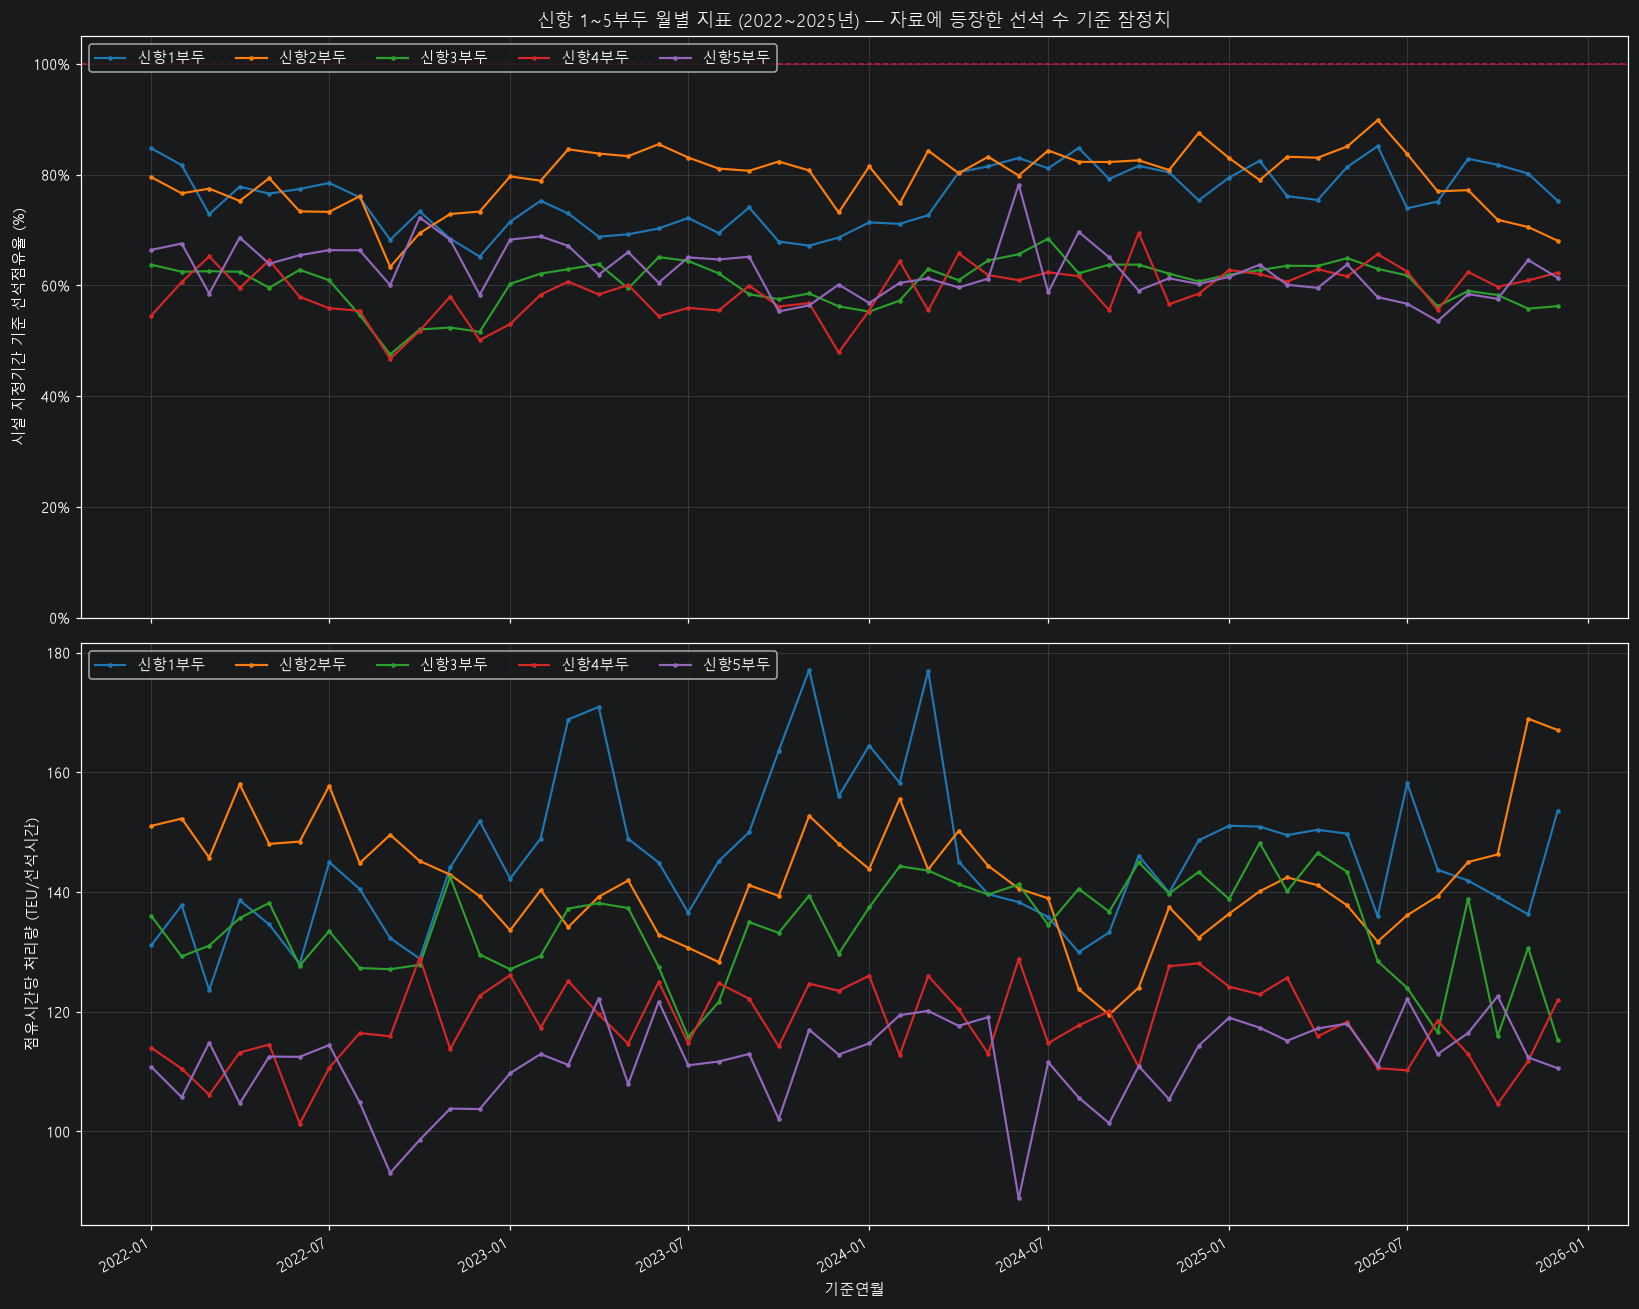

In [27]:
plt.rcParams.update({'figure.dpi':110, 'axes.grid':True, 'grid.alpha':0.25})
colors = plt.get_cmap('tab10').colors
fig, axes = plt.subplots(2,1,figsize=(15,12),sharex=True)
plot_specs = [('선석점유율_pct',1,'시설 지정기간 기준 선석점유율 (%)'),
              # ('선석당처리량_TEU',1000,'월별 선석당 처리량 (천TEU/선석)'),
              ('점유시간당처리량_TEU_h',1,'점유시간당 처리량 (TEU/선석시간)')]
for ax,(column,scale,label) in zip(axes,plot_specs):
    for i,pier in enumerate(PIERS):
        g = monthly.loc[monthly['부두'].eq(pier)].sort_values('기준연월')
        ax.plot(g['기준연월'],g[column]/scale,label=pier,color=colors[i],marker='o',markersize=2,linewidth=1.4)
    ax.set_ylabel(label)
    ax.legend(ncol=5,loc='upper left')
axes[0].set_ylim(0,105)
axes[0].yaxis.set_major_formatter(PercentFormatter(100))
axes[0].axhline(100,color='crimson',linestyle='--',linewidth=1)
axes[0].set_title('신항 1~5부두 월별 지표 (2022~2025년) — 자료에 등장한 선석 수 기준 잠정치')
axes[-1].set_xlabel('기준연월')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


각 先석의 월별 점유율도 확인합니다. 장기간 0%인 선석은 실제 미사용인지, 누락 또는 시설코드 변경인지 확인하세요.

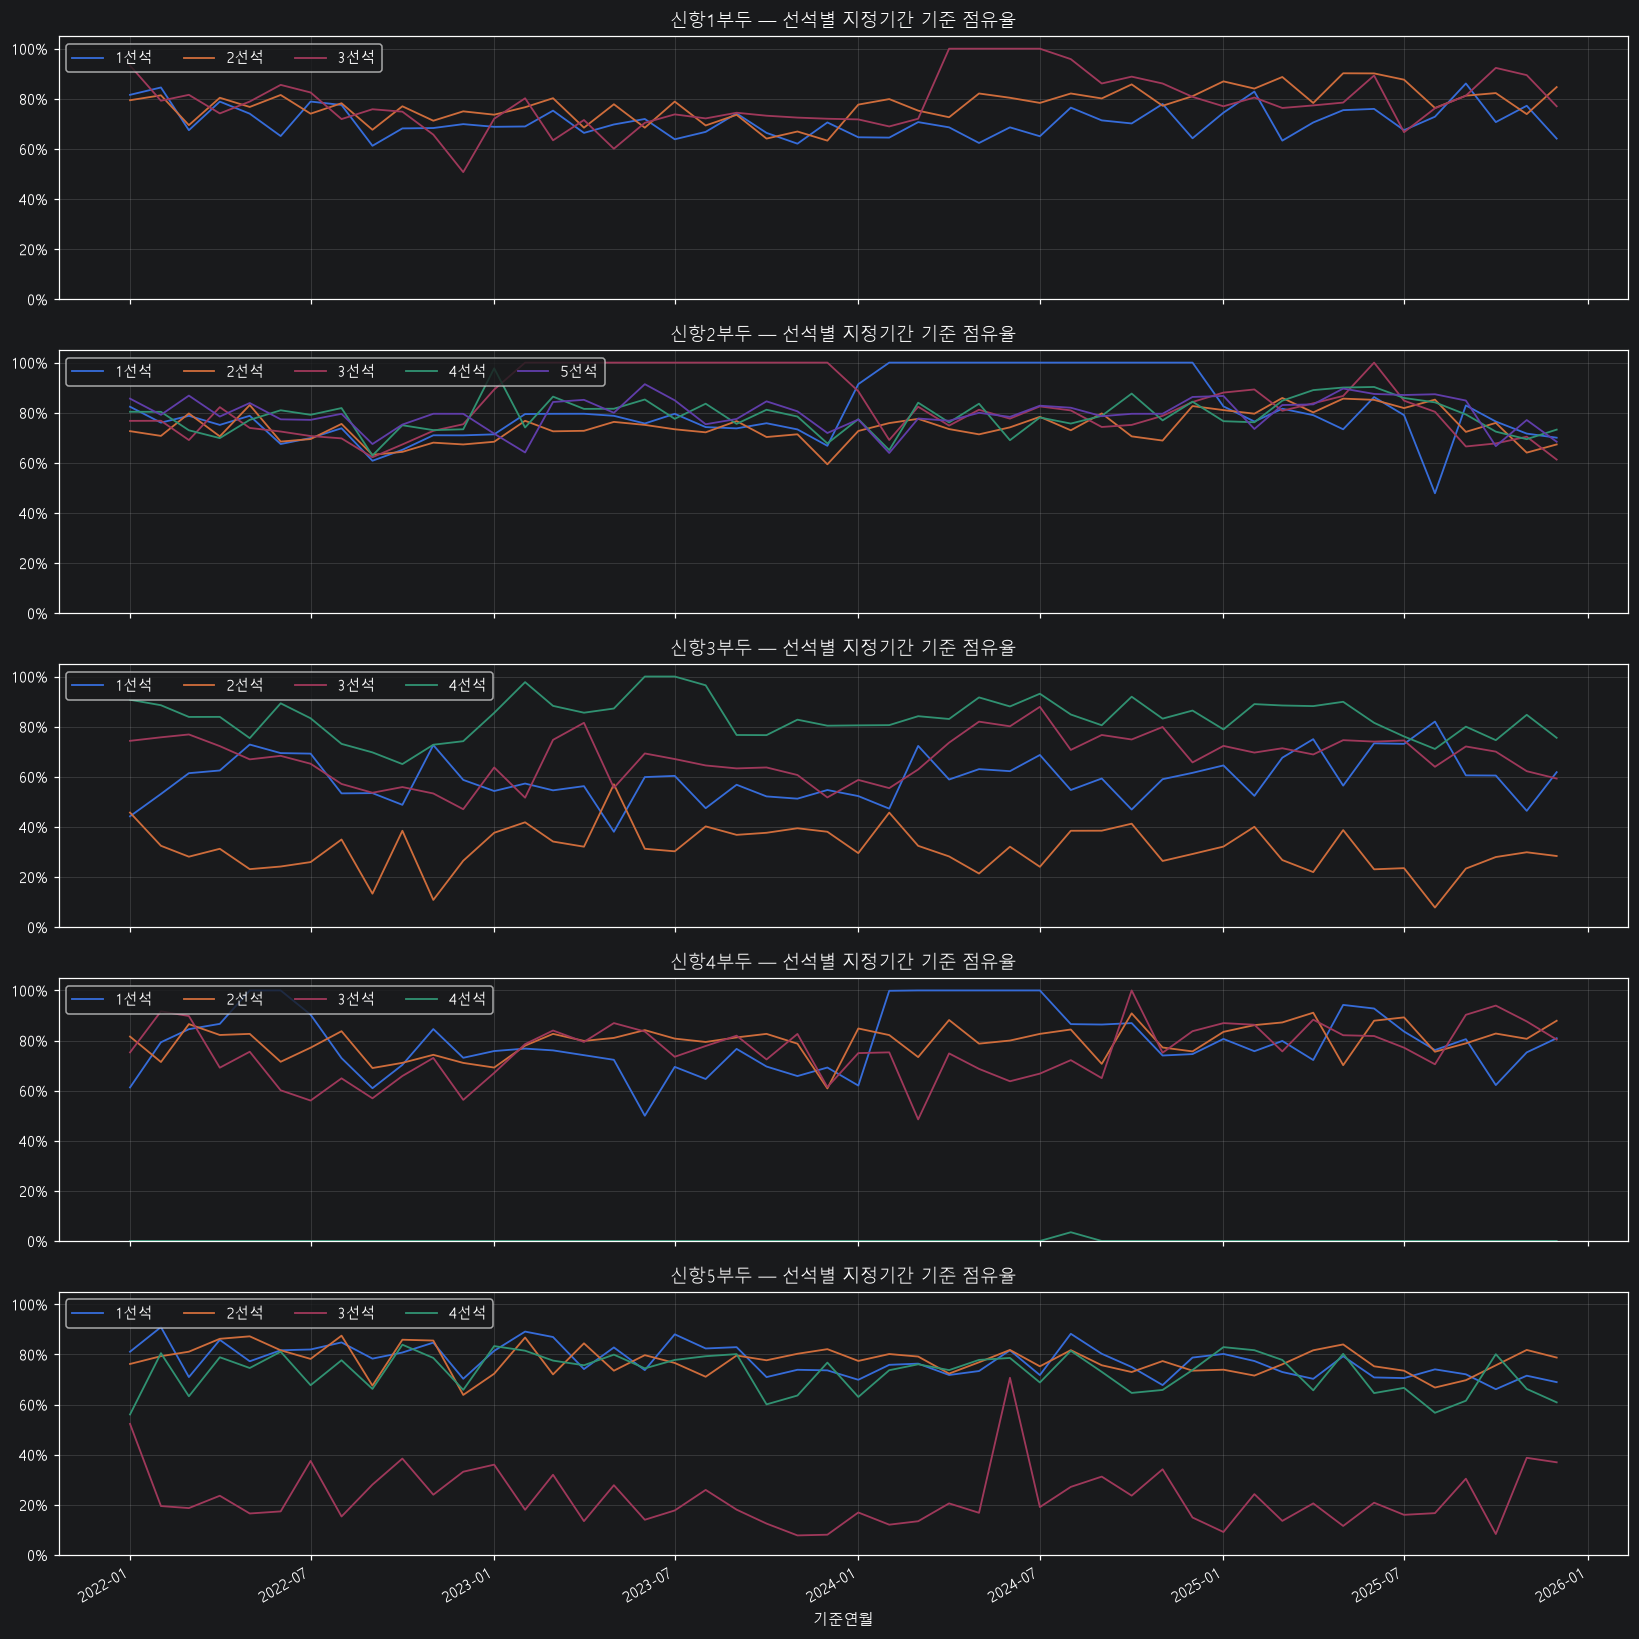

In [28]:
fig, axes = plt.subplots(5,1,figsize=(15,15),sharex=True)
for i,(ax,pier) in enumerate(zip(axes,PIERS)):
    for berth,g in berth_month.loc[berth_month['부두'].eq(pier)].groupby('선석'):
        ax.plot(g['기준연월'],g['선석점유율_pct'],label=f'{berth}선석',linewidth=1.2)
    ax.set_title(f'{pier} — 선석별 지정기간 기준 점유율')
    ax.set_ylim(0,105)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend(loc='upper left',ncol=5)
axes[-1].set_xlabel('기준연월')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## 6. 점유율과 재항시간의 비교
각 점은 해당 부두의 한 달입니다. 재항시간은 입출항 표본의 평균이며, 이 그래프만으로 혼잡의 인과관계나 선박 규모 효과를 판단할 수 없습니다. 총톤수는 월별 결과표에 보조 정보로 포함했지만 통계적으로 통제한 그래프는 아닙니다.

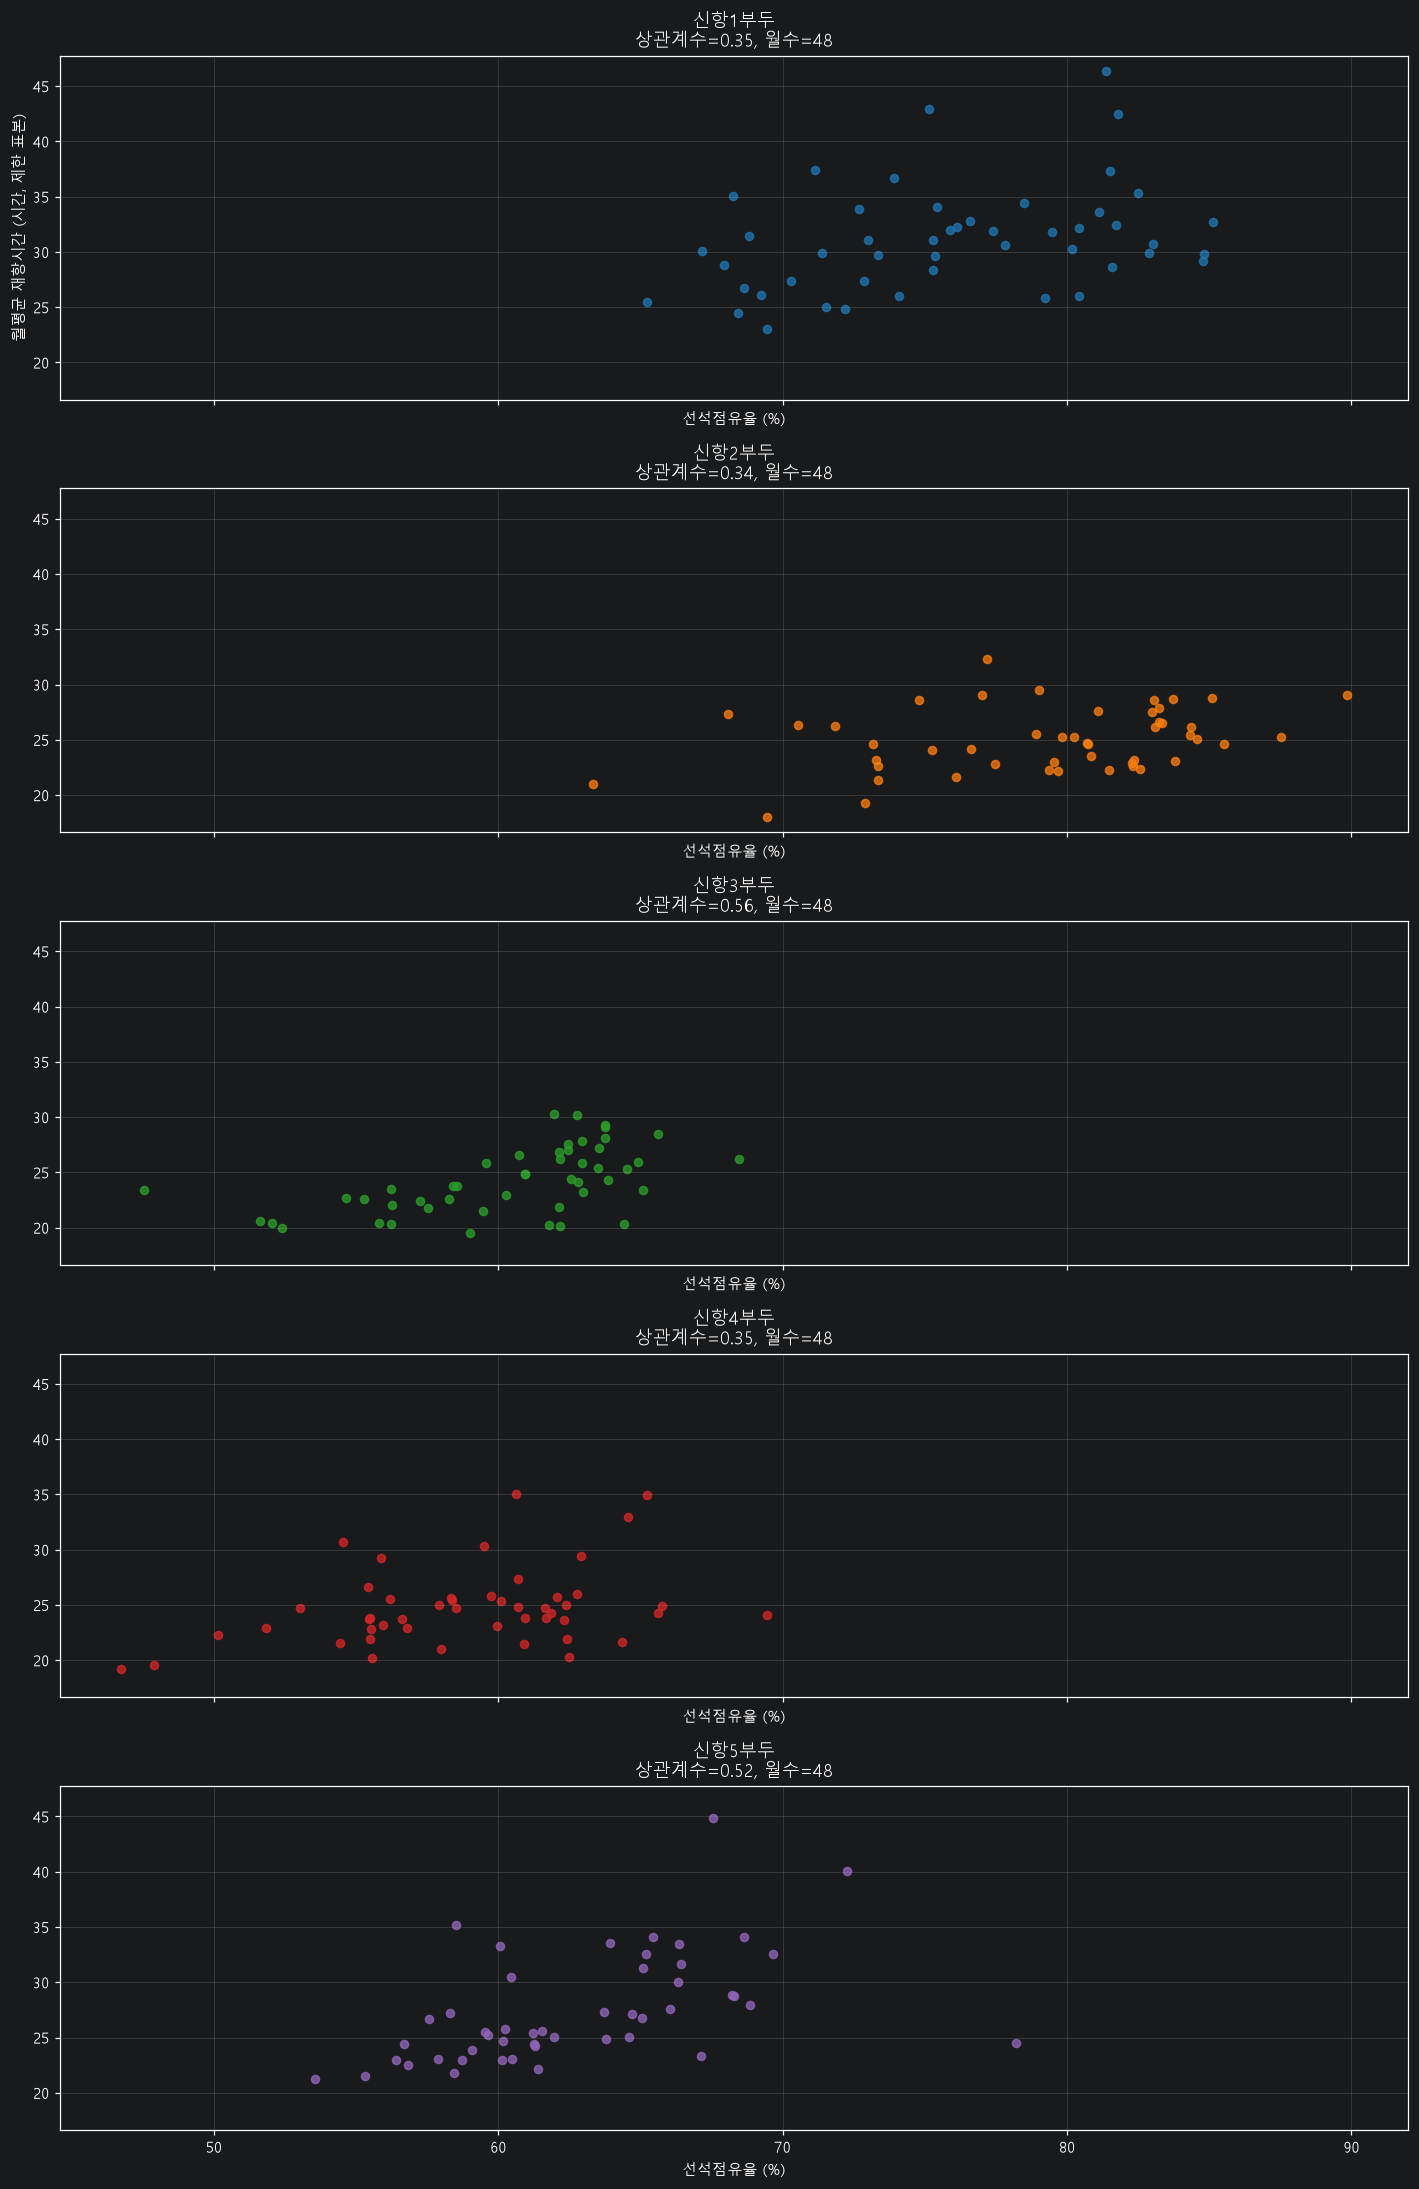

In [29]:
fig, axes = plt.subplots(5,1,figsize=(13,20),sharex=True,sharey=True)
for i,(ax,pier) in enumerate(zip(axes,PIERS)):
    g = monthly.loc[monthly['부두'].eq(pier)].dropna(subset=['선석점유율_pct','표본평균재항시간_h'])
    ax.scatter(g['선석점유율_pct'],g['표본평균재항시간_h'],color=colors[i],alpha=0.75,s=28)
    corr = g['선석점유율_pct'].corr(g['표본평균재항시간_h'])
    ax.set_title(f'{pier}\n상관계수={corr:.2f}, 월수={len(g)}')
    ax.set_xlabel('선석점유율 (%)')
axes[0].set_ylabel('월평균 재항시간 (시간, 제한 표본)')
plt.tight_layout()
plt.show()


## 8. 결과 저장
재실행하면 `berth_metrics_output` 폴더에 부두별 월별 결과, 선석별 월별 결과, 전체 요약 및 기간 점검표를 CSV로 저장합니다. 한글 Excel 호환 인코딩을 사용합니다.

**해석 시 유의:** 점유시간당 처리량과 점유율은 동일한 점유시간이 각각 분모와 분자에 들어갑니다. 두 지표 사이의 관계를 독립적인 효율성 증거로 해석하지 마세요. 월 물동량이 천TEU 단위로 반올림된 자료이므로 환산된 TEU도 그 정밀도를 넘지 않습니다.

In [30]:
# OUTPUT_DIR = Path('berth_metrics_output')
# OUTPUT_DIR.mkdir(exist_ok=True)
# monthly.to_csv(OUTPUT_DIR/'monthly_pier_metrics.csv',index=False,encoding='utf-8-sig')
# berth_month.to_csv(OUTPUT_DIR/'monthly_berth_occupancy.csv',index=False,encoding='utf-8-sig')
# summary.to_csv(OUTPUT_DIR/'pier_summary_2022_2025.csv',encoding='utf-8-sig')
# diagnostic.to_csv(OUTPUT_DIR/'designation_overlap_diagnostics.csv',index=False,encoding='utf-8-sig')
# invalid_designations.to_csv(OUTPUT_DIR/'invalid_designations.csv',index=False,encoding='utf-8-sig')
# sensitivity.to_csv(OUTPUT_DIR/'p4_berth_inventory_sensitivity.csv',index=False,encoding='utf-8-sig')
# print('저장 완료:', OUTPUT_DIR.resolve())
